# Лабораторная работа № 1. 
# Метод обратного распространения ошибки

## 1. Загрузка и подготовка данных

Используем исходное разделение MNIST: 60 000 изображений для обучения и 10 000 для проверки.

In [21]:
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np

In [22]:
data_path = Path("mnist.npz")
if not data_path.exists():
    url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
    print("Загружаем MNIST...")
    urlretrieve(url, data_path)

with np.load(data_path, allow_pickle=False) as data:
    train_images = data["x_train"]
    train_labels = data["y_train"].astype(np.int64)
    test_images = data["x_test"]
    test_labels = data["y_test"].astype(np.int64)

print(f"Обучающая выборка: {train_images.shape[0]} изображений")
print(f"Тестовая выборка:  {test_images.shape[0]} изображений")
print(f"Форма одного изображения: {train_images.shape[1:]}")
print(f"Форма массивов меток: {train_labels.shape} и {test_labels.shape}")
print(f"Форма одной метки: {train_labels[0].shape}, пример метки: {train_labels[0]}")

Обучающая выборка: 60000 изображений
Тестовая выборка:  10000 изображений
Форма одного изображения: (28, 28)
Форма массивов меток: (60000,) и (10000,)
Форма одной метки: (), пример метки: 5


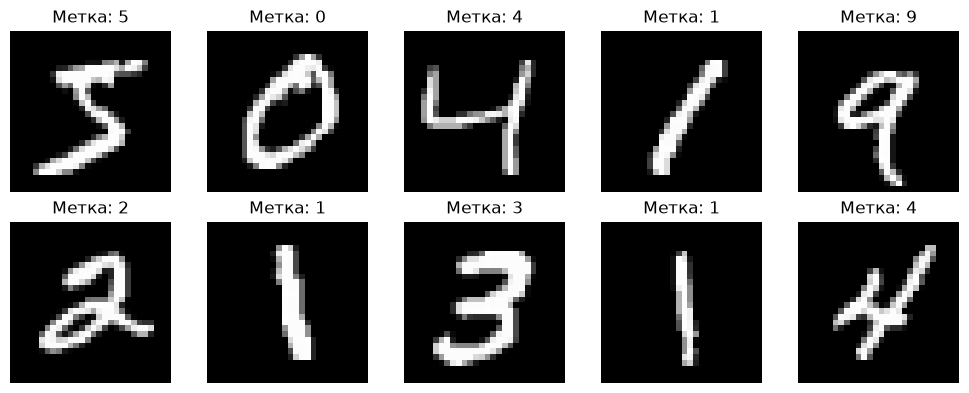

In [23]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.flat, train_images[:10], train_labels[:10]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Метка: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Каждое изображение разворачиваем в вектор из 784 чисел и делим значения пикселей на 255. Метки оставляем целыми числами от 0 до 9: они понадобятся как индексы правильных классов. `float32` уменьшает расход памяти и ускоряет матричные вычисления.

In [24]:
x_train = train_images.reshape(-1, 28 * 28).astype(np.float32) / 255.0
x_test = test_images.reshape(-1, 28 * 28).astype(np.float32) / 255.0

print("Входы сети:", x_train.shape, "и", x_test.shape)
print("Диапазон значений:", x_train.min(), "...", x_train.max())

Входы сети: (60000, 784) и (10000, 784)
Диапазон значений: 0.0 ... 1.0


## 2. Прямой проход и градиенты

Пусть в пачке $m$ изображений: $X$ имеет форму $(m, 784)$, $W_1$ — $(784, s)$, $b_1$ — $(s,)$, $W_2$ — $(s, 10)$, $b_2$ — $(10,)$. Прямой проход:

$$Z_1 = XW_1 + b_1, \qquad H = \operatorname{ReLU}(Z_1) = \max(0, Z_1),$$
$$Z_2 = HW_2 + b_2, \qquad P_{ij} = \frac{e^{Z_{2,ij}}}{\sum_{k=1}^{10} e^{Z_{2,ik}}}.$$

$$L = -\frac{1}{m}\sum_{i=1}^{m}\sum_{j=1}^{10} Y_{ij}\log P_{ij}.$$

**Обратный проход.** Производная softmax в сочетании с кросс-энтропией упрощается до разности вероятности и правильного ответа:

$$\frac{\partial L}{\partial Z_2} = D_2 = \frac{P-Y}{m},$$
$$\frac{\partial L}{\partial W_2} = H^\mathsf{T}D_2, \qquad
\frac{\partial L}{\partial b_2} = \sum_{i=1}^{m} D_{2,i},$$
$$D_1 = (D_2 W_2^\mathsf{T}) \odot \mathbf{1}[Z_1 > 0],$$
$$\frac{\partial L}{\partial W_1} = X^\mathsf{T}D_1, \qquad
\frac{\partial L}{\partial b_1} = \sum_{i=1}^{m} D_{1,i}.$$

Здесь $\odot$ — поэлементное умножение; производную ReLU в нуле принимаем равной нулю.

Веса инициализируем случайно с масштабом Хе: стандартное отклонение $\sqrt{2/n_{in}}$. Это помогает сохранить масштаб сигналов в сети с ReLU; смещения изначально равны нулю.

In [25]:
def initialize_network(input_size, hidden_size, output_size, rng):
    """Создать веса и смещения двух полносвязных слоёв."""
    return {
        "W1": (rng.standard_normal((input_size, hidden_size))
               * np.sqrt(2.0 / input_size)).astype(np.float32),
        "b1": np.zeros(hidden_size, dtype=np.float32),
        "W2": (rng.standard_normal((hidden_size, output_size))
               * np.sqrt(2.0 / hidden_size)).astype(np.float32),
        "b2": np.zeros(output_size, dtype=np.float32),
    }


def forward(x, params):
    """Вернуть промежуточные значения и вероятности классов."""
    z1 = x @ params["W1"] + params["b1"]
    hidden = np.maximum(z1, 0)
    logits = hidden @ params["W2"] + params["b2"]
    shifted_logits = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(shifted_logits)
    probabilities = exp_logits / exp_logits.sum(axis=1, keepdims=True)
    return z1, hidden, shifted_logits, probabilities


def backward(x, labels, params, z1, hidden, probabilities):
    """Вычислить градиенты средней ошибки по одной пачке."""
    batch_size = x.shape[0]
    # Вычитание 1 в столбце правильного класса эквивалентно P - Y.
    d_logits = probabilities.copy()
    d_logits[np.arange(batch_size), labels] -= 1
    d_logits /= batch_size

    gradients = {}
    gradients["W2"] = hidden.T @ d_logits
    gradients["b2"] = d_logits.sum(axis=0)
    d_hidden = d_logits @ params["W2"].T
    d_z1 = d_hidden * (z1 > 0)
    gradients["W1"] = x.T @ d_z1
    gradients["b1"] = d_z1.sum(axis=0)
    return gradients

In [26]:
def evaluate(x, labels, params, batch_size=1024):
    total_loss = 0.0
    total_errors = 0
    for start in range(0, len(x), batch_size):
        x_batch = x[start:start + batch_size]
        y_batch = labels[start:start + batch_size]
        _, _, logits, probabilities = forward(x_batch, params)

        # -log(p правильного класса) = log(sum(exp(logits))) - logits[класс].
        losses = np.log(np.exp(logits).sum(axis=1)) - logits[np.arange(len(y_batch)), y_batch]
        total_loss += losses.sum(dtype=np.float64)
        total_errors += np.count_nonzero(probabilities.argmax(axis=1) != y_batch)

    return total_loss / len(x), total_errors / len(x)

## 3. Обучение

In [27]:
hidden_size = 300
learning_rate = 0.1
batch_size = 64
epochs = 20

# Фиксируем генератор, чтобы и начальные веса, и перемешивание повторялись.
rng = np.random.default_rng(42)
params = initialize_network(784, hidden_size, 10, rng)
history = []
training_start = perf_counter()

for epoch in range(1, epochs + 1):
    epoch_start = perf_counter()
    indices = rng.permutation(len(x_train))

    for start in range(0, len(x_train), batch_size):
        batch_indices = indices[start:start + batch_size]
        x_batch = x_train[batch_indices]
        y_batch = train_labels[batch_indices]

        z1, hidden, _, probabilities = forward(x_batch, params)
        gradients = backward(x_batch, y_batch, params, z1, hidden, probabilities)
        for name in params:
            params[name] -= learning_rate * gradients[name]

    train_loss, train_error = evaluate(x_train, train_labels, params)
    elapsed = perf_counter() - epoch_start
    history.append((train_loss, train_error))
    print(f"Эпоха {epoch:2d}/{epochs}: "
          f"кросс-энтропия = {train_loss:.4f}, "
          f"ошибка классификации = {train_error:.2%}, "
          f"время = {elapsed:.1f} с")

print(f"Общее время обучения: {perf_counter() - training_start:.1f} с")

Эпоха  1/20: кросс-энтропия = 0.2100, ошибка классификации = 5.97%, время = 3.6 с
Эпоха  2/20: кросс-энтропия = 0.1469, ошибка классификации = 4.05%, время = 1.9 с
Эпоха  3/20: кросс-энтропия = 0.1169, ошибка классификации = 3.28%, время = 2.0 с
Эпоха  4/20: кросс-энтропия = 0.0932, ошибка классификации = 2.59%, время = 2.5 с
Эпоха  5/20: кросс-энтропия = 0.0777, ошибка классификации = 2.11%, время = 2.4 с
Эпоха  6/20: кросс-энтропия = 0.0680, ошибка классификации = 1.85%, время = 2.6 с
Эпоха  7/20: кросс-энтропия = 0.0595, ошибка классификации = 1.61%, время = 2.0 с
Эпоха  8/20: кросс-энтропия = 0.0508, ошибка классификации = 1.29%, время = 2.2 с
Эпоха  9/20: кросс-энтропия = 0.0442, ошибка классификации = 1.14%, время = 3.3 с
Эпоха 10/20: кросс-энтропия = 0.0399, ошибка классификации = 0.98%, время = 3.2 с
Эпоха 11/20: кросс-энтропия = 0.0367, ошибка классификации = 0.85%, время = 2.2 с
Эпоха 12/20: кросс-энтропия = 0.0345, ошибка классификации = 0.77%, время = 4.0 с
Эпоха 13/20: кро

## 4. Проверка на тестовой выборке

In [28]:
test_loss, test_error = evaluate(x_test, test_labels, params)
print(f"Кросс-энтропия на тестовой выборке: {test_loss:.4f}")
print(f"Ошибка классификации на тестовой выборке: {test_error:.2%}")
print(f"Точность на тестовой выборке: {1 - test_error:.2%}")

Кросс-энтропия на тестовой выборке: 0.0618
Ошибка классификации на тестовой выборке: 1.84%
Точность на тестовой выборке: 98.16%
